### Use CIFAR10 open dataset to generate 2000 images for not coin dataset (excluded class 0:airplane)






In [ ]:
# Import libraries
# CIFAR-10 dataset loader from Keras
from tensorflow.keras.datasets import cifar10

# Save images in JPG format
from PIL import Image

# Array operations
import numpy as np

# For directory and file handling
import os

# ---Load CIFAR-10 Dataset---
# CIFAR-10 contains 60,000 32x32 color images in 10 classes
# Split into 50,000 training and 10,000 test images
(x_train, y_train), (_, _) = cifar10.load_data()

# Print dataset shape for confirmation
print("CIFAR-10 Loaded:")
print("x_train shape:", x_train.shape) # Shape: (50000, 32, 32, 3)
print("y_train shape:", y_train.shape) # Shape: (50000, 1)

# ---Filter Out Class 0 (Airplane)---
# Classes 1-9 will be used for "Not Coin"
mask = y_train.flatten() != 0  # Exclude label 0 (airplane)
not_coin_images = x_train[mask] # Keep only images where label != 0 (classes 1–9)
not_coin_labels = y_train[mask] # Keep only corresponding labels (classes 1–9)

print("Filtered Not Coin images shape:", not_coin_images.shape)

# ---Create output directory---
output_dir = "Not_Coin_Images"
os.makedirs(output_dir, exist_ok=True) # Create directory if it doesn't already exist

# ---Check if indices file exists---
# Reuse same random subset every run
indices_file = "not_coin_indices.txt"
if os.path.exists(indices_file):
    # Load existing indices to guarantee same dataset
    print("Loading saved indices from not_coin_indices.txt")
    indices = np.loadtxt(indices_file, dtype=int)
else:
    # Randomly select 2000 indices and save them
    np.random.seed(42)  # Fix random seed for reproducibility
    indices = np.random.choice(len(not_coin_images), size=2000, replace=False)
    np.savetxt(indices_file, indices, fmt='%d')
    print("Selected indices saved to not_coin_indices.txt")

# ---Extract selected images---
selected_images = not_coin_images[indices]

# ---Save selected images to folder---
for i, img_array in enumerate(selected_images):
    img = Image.fromarray(img_array)
    img = img.resize((64, 64))  # Resize to 64x64 for consistency
    img.save(os.path.join(output_dir, f"notcoin_{i}.jpg"))

# ---Confirmation---
print(f"Saved {len(selected_images)} Not Coin images to '{output_dir}/'")
print("Saved indices file: not_coin_indices.txt")


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
CIFAR-10 Loaded:
x_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
Filtered Not Coin images shape: (45000, 32, 32, 3)
Selected indices saved to not_coin_indices.txt
Saved 2000 Not Coin images to 'Not_Coin_Images/'
Saved indices file: not_coin_indices.txt


### Zip & download the not coin dataset zip files

In [ ]:
# For creating ZIP archives
import shutil
# For downloading files in Colab
from google.colab import files

# ---Zip the folder---
shutil.make_archive("Not_Coin_Images", 'zip', "Not_Coin_Images")
# ---Download ZIP---
files.download("Not_Coin_Images.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Mount google drive to use the dataset

In [ ]:
# Import Colab drive module
from google.colab import drive

# ---Mount Google Drive---
# Mount Google Drive to access files
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Paths to Coin and Not_Coin Dataset ZIP Files

In [ ]:
coin_zip_path = "/content/drive/MyDrive/Colab Notebooks/Data/Coin_Dataset.zip"
not_coin_zip_path = "/content/drive/MyDrive/Colab Notebooks/Data/Not_Coin_Dataset.zip"



In [ ]:
import zipfile

# Define the path to the Not_Coin_Dataset.zip file
not_coin_zip_path = "/content/drive/MyDrive/Colab Notebooks/Data/Not_Coin_Dataset.zip"

# Unzip Not_Coin_Dataset.zip
with zipfile.ZipFile(not_coin_zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/drive/MyDrive/Colab Notebooks/Data/Not_Coin_Dataset")

# Now point to the unzipped folder
not_coin_dir = "/content/drive/MyDrive/Colab Notebooks/Data/Not_Coin_Dataset"

In [ ]:
target_root = "/content/drive/MyDrive/Colab Notebooks/Data/Split_Dataset"  # Target directory for split dataset
not_coin_dir = "/content/drive/MyDrive/Colab Notebooks/Data/Not_Coin_Dataset.zip"  # Folder with Not_Coin images (after unzip)

### Split Not_Coin Images into Train, Validation, and Test Sets (to have same structure with coin dataset)

In [ ]:
import shutil
# For splitting dataset
from sklearn.model_selection import train_test_split

# ---Create split folders---
# Make train, valid, and test directories for Not_Coin
for split in ["train", "valid", "test"]:
    os.makedirs(os.path.join(target_root, split, "Not_Coin"), exist_ok=True)

# Get all Not_Coin images
# List all JPG files in the Not_Coin folder
all_images = [f for f in os.listdir(not_coin_dir) if f.endswith(".jpg")]

# ---Split dataset---
# Split: 70% train, 15% valid, 15% test
# random_state=42 ensures same split every run for reproducibility
train_imgs, temp_imgs = train_test_split(all_images, test_size=0.3, random_state=42)
valid_imgs, test_imgs = train_test_split(temp_imgs, test_size=0.5, random_state=42)

# ---Helper function to copy images---
def copy_images(file_list, src_dir, target_dir):
    for fname in file_list:
        shutil.copy(os.path.join(src_dir, fname), os.path.join(target_dir, fname))

# ---Copy images to respective folders---
copy_images(train_imgs, not_coin_dir, os.path.join(target_root, "train", "Not_Coin"))
copy_images(valid_imgs, not_coin_dir, os.path.join(target_root, "valid", "Not_Coin"))
copy_images(test_imgs, not_coin_dir, os.path.join(target_root, "test", "Not_Coin"))

# ---Confirmation---
print("Not_Coin split into train/valid/test in Google Drive")


Not_Coin split into train/valid/test in Google Drive


### Move Coin Dataset images to the same folder: Spilt_Dataset

In [ ]:
# ---Move Coin images to train/valid/test folders---
for split in ["train", "valid", "test"]:
    src = os.path.join(coin_dir, split)              # Source folder for current split
    dst = os.path.join(target_root, split, "Coin")   # Target folder for Coin images
    os.makedirs(dst, exist_ok=True)                  # Create target folder if missing
    for fname in os.listdir(src):                    # Loop through all files in source
        shutil.move(os.path.join(src, fname), os.path.join(dst, fname)) # Move file to target

# ---Confirmation---
print("Coin moved into train/valid/test in Google Drive")


Coin moved into train/valid/test in Google Drive


In [ ]:
dataset_path = "/content/drive/MyDrive/Colab Notebooks/Data/Split_Dataset"


### Check Total Images in Train/Valid/Test in Spilt_Dataset

In [ ]:
import os

# ---Define dataset path---
dataset_path = "/content/drive/MyDrive/Colab Notebooks/Data/Split_Dataset"

# ---Function to count images---
# Counts all image files (.jpg, .png, .jpeg) in a directory and subdirectories
def count_images(directory):
    total = 0
    for root, _, files in os.walk(directory): # Walk through all subfolders
        total += len([f for f in files if f.lower().endswith(('.jpg', '.png', '.jpeg'))]) # Count image files
    return total

# ---Print image counts for each dataset split---
print("Total train images:", count_images(os.path.join(dataset_path, "train")))
print("Total valid images:", count_images(os.path.join(dataset_path, "valid")))
print("Total test images:", count_images(os.path.join(dataset_path, "test")))


Total train images: 3536
Total valid images: 505
Total test images: 403


### Dataset path ans class labels


In [ ]:
import os  # For file and directory operations
import cv2 # For image loading and resizing
import numpy as np # For array operations
from sklearn.preprocessing import LabelEncoder  # For encoding class labels
from sklearn.model_selection import train_test_split # For splitting dataset
from sklearn.utils import shuffle # For shuffling data

# ---Define dataset path & image settings---
dataset_path = "/content/drive/MyDrive/Colab Notebooks/Data/Split_Dataset"

img_size = 224 # Resize images (224x224)

# ---Define class labels---
classes = ["Coin", "Not_Coin"]

## Load and Preprocess images from Spilt_Dataset for Training


In [ ]:
import os  # For file and directory operations
import cv2 # For image loading and resizing

splits = ["train", "valid", "test"]
images = [] # To store image arrays
labels = [] # To store corresponding class labels

for split in splits:
    for class_name in classes:  # Coin, Not_Coin
        class_path = os.path.join(dataset_path, split, class_name)  # Path to class folder

        if not os.path.exists(class_path):  # Check if folder exists
            print(f"Folder not found: {class_path}")
            continue

        # Get all image filenames in the folder
        filenames = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

        for fname in filenames:
            img_path = os.path.join(class_path, fname) # Full path to image
            img = cv2.imread(img_path) # Load image

            if img is not None:
                img = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
                images.append(img)
                labels.append(class_name)
            else:
                print("Failed to load:", img_path)

print(f"Loaded {len(images)} images total.")


Loaded 4444 images total.


### Check structure in Spilt_Dataset
This code verifies that the `train`, `valid`, and `test` folders exist and contain the expected class folders (`Coin`, `Not_Coin`). It also attempts to load and resize images to check dataset integrity. This block is for confirmation only and is not used in model training.

In [15]:
import os
import cv2

# ---Loop through train/valid/test subfolders and then class folders---
splits = ["train", "valid", "test"] # Dataset splits
class_names = ["Coin", "Not_Coin"] # Class folder names

for split in splits:
    split_path = os.path.join(dataset_path, split) # Path to split folder
    print(f"Processing split: {split}")

    for class_name in class_names:
        class_path = os.path.join(split_path, class_name)
        print(f"  Processing class: {class_name} in {split}") # Path to class folder

        if not os.path.exists(class_path):
            print(f"Warning: Class path does not exist: {class_path}")
            continue

        filenames = os.listdir(class_path) # List all files in class folder

        for fname in filenames:
            img_path = os.path.join(class_path, fname) # Full image path


            # Check if file is an image
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                # Load image
                img = cv2.imread(img_path)

                if img is not None:
                   # Resize image to uniform size
                    img = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA)
                    images.append(img) # Add image to list
                    labels.append(class_name) # Add corresponding label
                else:
                    print("Failed to load image:", img_path)
            else:
                print(f"Skipping non-image file: {img_path}")


Processing split: train
  Processing class: Coin in train
Skipping non-image file: /content/drive/MyDrive/Colab Notebooks/Data/Split_Dataset/train/Coin/_classes.csv
  Processing class: Not_Coin in train
Processing split: valid
  Processing class: Coin in valid
Skipping non-image file: /content/drive/MyDrive/Colab Notebooks/Data/Split_Dataset/valid/Coin/_classes.csv
  Processing class: Not_Coin in valid
Processing split: test
  Processing class: Coin in test
Skipping non-image file: /content/drive/MyDrive/Colab Notebooks/Data/Split_Dataset/test/Coin/_classes.csv
  Processing class: Not_Coin in test


## Preprocess Dataset: Normalize & Encode Labels

In [ ]:
import numpy as np # For numerical operations
from sklearn.preprocessing import LabelEncoder # For encoding class labels

# ---Convert lists to NumPy arrays---
images = np.array(images, dtype="float32") # Convert image list to NumPy array
labels = np.array(labels) # Convert label list to NumPy array

# ---Normalize pixel values---
images /= 255.0

# Encode labels ('Coin' → 0, 'Not_Coin' → 1)
label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels)

# ---Print dataset summary---
print("\nDataset Summary")
print("Loaded image shape:", images.shape) #total_images, 224, 224, 3
print("Sample raw labels (first 10):", labels[:10]) # Before encoding
print("Class mapping:")  # Shows label → integer mapping
for class_name, encoded_val in zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)):
    print(f"{class_name} → {encoded_val}")
print("Encoded labels example (first 10):", labels_encoded[:10]) # After encoding
print("Label encoded:", np.unique(labels_encoded, return_counts=True)) # Class distribution



Dataset Summary
Loaded image shape: (4444, 224, 224, 3)
Sample raw labels (first 10): ['Coin' 'Coin' 'Coin' 'Coin' 'Coin' 'Coin' 'Coin' 'Coin' 'Coin' 'Coin']
Class mapping:
Coin → 0
Not_Coin → 1
Encoded labels example (first 10): [0 0 0 0 0 0 0 0 0 0]
Label encoded: (array([0, 1]), array([2444, 2000]))


# Spilt dataset for training and testing

In [ ]:
# For splitting dataset into train/test
from sklearn.model_selection import train_test_split

# ---Shuffle and split dataset---
# Split dataset into 90% training and 10% testing
# random_state=42 ensures reproducibility
train_x, test_x, train_y, test_y = train_test_split(images, labels_encoded, test_size=0.1, random_state=42)


# ---Print shapes of the splits---
print("\nTrain/Test shapes:")
print("train_x:", train_x.shape)
print("train_y:", train_y.shape)
print("test_x:", test_x.shape)
print("test_y:", test_y.shape)


Train/Test shapes:
train_x: (3999, 224, 224, 3)
train_y: (3999,)
test_x: (445, 224, 224, 3)
test_y: (445,)


### Initial Model: Baseline Neural Network
This is the first version of the model created for binary classification. It uses:
- A Flatten layer to preprocess input images of shape (224, 224, 3).
- Two Dense layers with 256 and 50 units using sigmoid activation.
- A final Dense layer with 1 unit and sigmoid activation for binary classification (coin vs not-coin).

The results from training this model were **not satisfactory**, leading to further improvements later.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
from tensorflow import keras

# Build the model
model = keras.Sequential([
keras.layers.Flatten(input_shape=(224,224,3)),
#keras.layers.Dropout(0.5),
keras.layers.Dense(256, activation=tf.nn.sigmoid),
keras.layers.Dense(50, activation=tf.nn.sigmoid),
keras.layers.Dense(1, activation=tf.nn.sigmoid)]) # Changed to 1 unit with sigmoid for binary classification
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │    38,535,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 50)             │        12,850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,548,325 (147.05 MB)

 Trainable params: 38,548,325 (147.05 MB)

 Non-trainable params: 0 (0.00 B)

### Initial Model: Training and Results


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(train_x, train_y, epochs=10, batch_size=32, validation_split=0.1)


Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 84s 727ms/step - accuracy: 0.5298 - loss: 0.7697 - val_accuracy: 0.5225 - val_loss: 0.6925
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 81s 719ms/step - accuracy: 0.5209 - loss: 0.6905 - val_accuracy: 0.5225 - val_loss: 0.7063
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 80s 703ms/step - accuracy: 0.5281 - loss: 0.6921 - val_accuracy: 0.5225 - val_loss: 0.6934
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 84s 716ms/step - accuracy: 0.5532 - loss: 0.6896 - val_accuracy: 0.5225 - val_loss: 0.7205
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 81s 710ms/step - accuracy: 0.5449 - loss: 0.6927 - val_accuracy: 0.5225 - val_loss: 0.7052
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 80s 697ms/step - accuracy: 0.5518 - loss: 0.6889 - val_accuracy: 0.5225 - val_loss: 0.6940
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 82s 698ms/step - accuracy: 0.5490 - loss: 0.6884 - val_accuracy: 0.5225 - val_loss: 0.6958
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 83s 702ms/step - accuracy: 0.5458 - loss: 0

# Improved Model: Convolutional Neural Network (CNN)

This improved model was developed after the initial baseline model failed to achieve satisfactory results. 

**Key improvements:**
- Added Convolutional (`Conv2D`) and MaxPooling (`MaxPooling2D`) layers to extract spatial features from images.
- Introduced Dropout layers to prevent overfitting.
- Changed activation functions and optimizer for better convergence.
- Designed specifically for binary classification of coin vs not-coin images.

This is the model used for training and reporting final results in the project.


In [ ]:
from tensorflow.keras.models import Sequential # For sequential model architecture
from tensorflow.keras.layers import Conv2D, MaxPooling2D # For convolution and pooling layers
from tensorflow.keras.layers import Flatten, Dense, Dropout # For flattening, dense layers, and dropout regularization

# ---Define CNN model architecture---
model = Sequential([
    # Convolutional Layer 1: 32 filters, 3x3 kernel, ReLU activation, input shape 224x224x3 (RGB image)
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    MaxPooling2D(2, 2), # Max Pooling Layer 1: Downsample feature maps (2x2 pool size)


    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),  # Max Pooling Layer 2
    Flatten(),
    Dense(128, activation='relu'), # Fully connected layer with 128 neurons and ReLU activation
    Dropout(0.3), # Dropout layer to reduce overfitting (drop 30% of neurons during training)
    Dense(1, activation='sigmoid')  # Output layer: 1 neuron with sigmoid activation for binary classification
])

# ---Compile the model---
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'] )# Loss function: Binary crossentropy for binary classification

# ---Print model summary---
# Display architecture, parameters, and layer details
model.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,907,521 (91.20 MB)

 Trainable params: 23,907,521 (91.20 MB)

 Non-trainable params: 0 (0.00 B)

# Training the Improved Model & Result




In [ ]:
# ---Train the model---
history = model.fit(
    train_x, train_y, # Training data and labels
    epochs=30, # Number of times the model sees the entire dataset
    batch_size=32, # Number of samples per gradient update
    validation_split=0.2,  # Use 20% of training data for validation
    verbose=1  # Show progress bar and training details
)


Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 280s 3s/step - accuracy: 0.8223 - loss: 0.9224 - val_accuracy: 1.0000 - val_loss: 0.0038
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 318s 3s/step - accuracy: 0.9886 - loss: 0.0504 - val_accuracy: 0.9638 - val_loss: 0.1942
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 277s 3s/step - accuracy: 0.9909 - loss: 0.0295 - val_accuracy: 0.9975 - val_loss: 0.0141
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 322s 3s/step - accuracy: 0.9971 - loss: 0.0079 - val_accuracy: 1.0000 - val_loss: 4.0150e-04
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 319s 3s/step - accuracy: 1.0000 - loss: 6.5591e-04 - val_accuracy: 1.0000 - val_loss: 9.9341e-05
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 321s 3s/step - accuracy: 1.0000 - loss: 7.5585e-05 - val_accuracy: 1.0000 - val_loss: 1.3408e-04
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 318s 3s/step - accuracy: 0.9933 - loss: 0.0231 - val_accuracy: 0.9200 - val_loss: 0.1851
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 269s 3s/step - accuracy: 0.9810 - los

# Save the model

In [ ]:
model.save("coin_or_not_coin_model.keras")


In [ ]:
from tensorflow.keras.models import load_model

model = load_model("coin_or_not_coin_model.keras")


# Load Trained Model and Predict Classes for Test Images

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 492ms/step


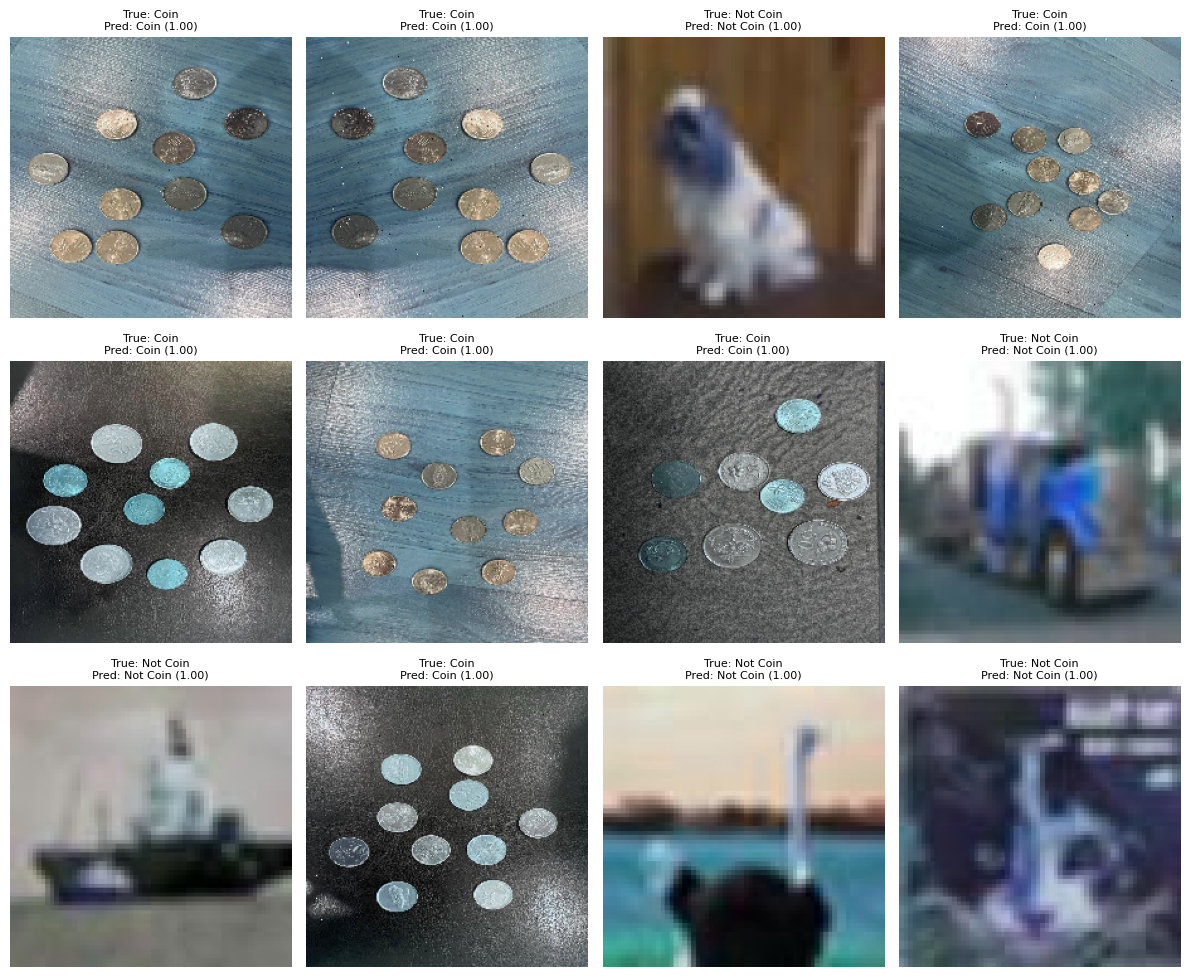

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

# ---Load the saved model---
model = load_model("coin_or_not_coin_model.keras")

# ---Define test images folder(from coin and not coin test images)---
test_folder = "test_images"

# Get list of all image files
image_files = [f for f in os.listdir(test_folder) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

# ---Set up plot for displaying predictions---
plt.figure(figsize=(12, 8))

# ---Loop through test images and make predictions---
for idx, file in enumerate(image_files):
    img_path = os.path.join(test_folder, file) # Full path to the image
    img = image.load_img(img_path, target_size=(224, 224)) # Load and resize image
    img_array = image.img_to_array(img) # Convert image to numpy array
    img_array = np.expand_dims(img_array, axis=0) / 255.0 # Normalize and add batch dimension

    prediction = model.predict(img_array)[0][0] # Get prediction probability
    label = "Coin" if prediction > 0.5 else "Not Coin" # Classify based on threshold

    # ---Show image with prediction label---
    plt.subplot(3, 4, idx + 1) # Arrange images in 3x4 grid
    plt.imshow(img)
    plt.title(f"{label}\n{prediction:.2f}") # Display label and probability
    plt.axis("off")

    if idx == 11:  # Limit to showing first 12 images
        break

# ---Show all plotted images---
plt.tight_layout()
plt.show()


In [ ]:
# To load the trained model
from tensorflow.keras.models import load_model
# ---Evaluate the model on the test set---
test_loss, test_accuracy = model.evaluate(test_x, test_y)

# ---Print the results---
print(f"Test Accuracy: {test_accuracy:.4f}, Test Loss: {test_loss:.4f}")

14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 693ms/step - accuracy: 1.0000 - loss: 6.1822e-06
Test Accuracy: 1.0000, Test Loss: 0.0000


# Classification report

In [ ]:
# For evaluation metrics
from sklearn.metrics import confusion_matrix, classification_report

# ---Make predictions on the test set---
# Get predicted probabilities from the model
y_pred_prob = model.predict(test_x)
# Convert probabilities to binary class labels (threshold 0.5)
y_pred = (y_pred_prob > 0.5).astype(int)

# ---Print confusion matrix and classification report---
print(confusion_matrix(test_y, y_pred)) # Show confusion matrix
print(classification_report(test_y, y_pred, target_names=["Coin", "Not Coin"])) # Show precision, recall, F1-score


14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 711ms/step
[[248   0]
 [  0 197]]
              precision    recall  f1-score   support

        Coin       1.00      1.00      1.00       248
    Not Coin       1.00      1.00      1.00       197

    accuracy                           1.00       445
   macro avg       1.00      1.00      1.00       445
weighted avg       1.00      1.00      1.00       445



# Confusion Matrix

14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 778ms/step


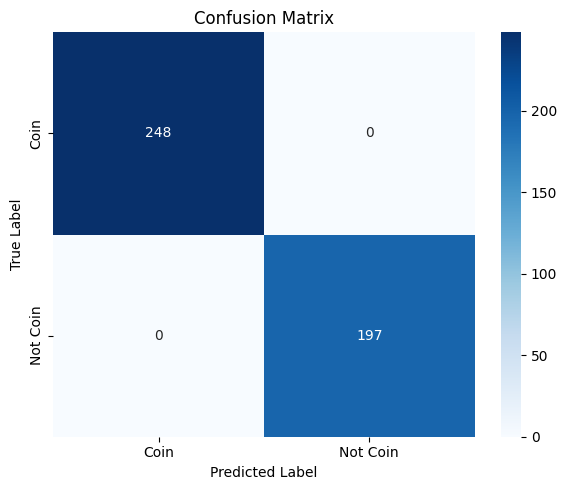

In [ ]:
import numpy as np
import seaborn as sns # For heatmap visualization
import matplotlib.pyplot as plt # For plotting
from sklearn.metrics import confusion_matrix # To generate confusion matrix

# ---Predict on test data---
y_pred_probs = model.predict(test_x) # Get predicted probabilities
y_pred = (y_pred_probs > 0.5).astype("int32").flatten()  # Convert probabilities to 0 or 1 and flatten array
y_true = test_y.flatten() # Flatten true labels for comparison

# ---Generate confusion matrix---
cm = confusion_matrix(y_true, y_pred) # Create confusion matrix
labels = ['Coin', 'Not Coin'] # Class names for axis labels

# Plot confusion matrix
plt.figure(figsize=(6, 5)) # Set figure size
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted Label')  # Label for X-axis
plt.ylabel('True Label') # Label for Y-axis
plt.title('Confusion Matrix') # Title of the plot
plt.tight_layout()  # Adjust layout to fit
plt.show() # Display the plot


# Training and Validation Accuracy & Loss Curves



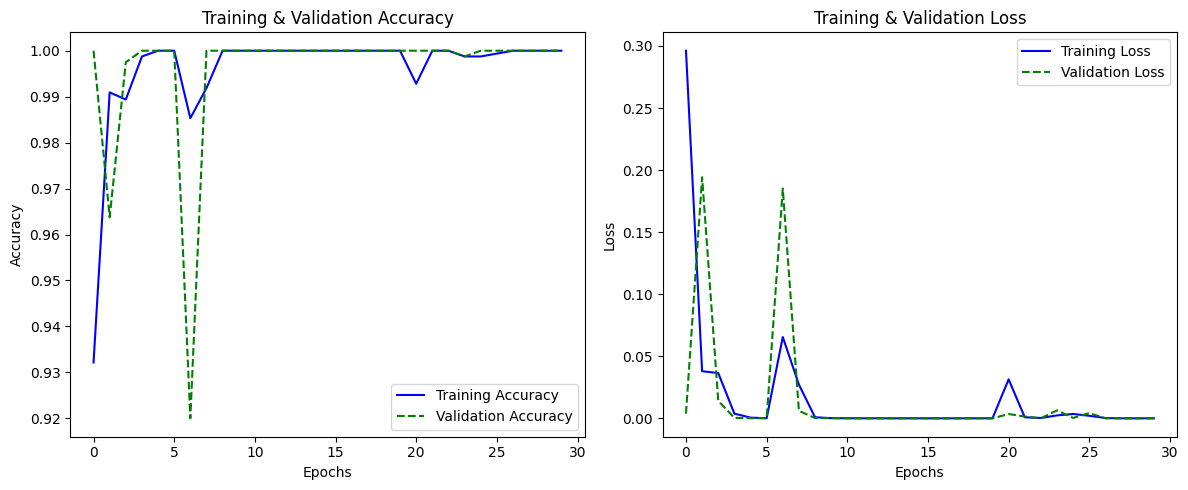

In [ ]:
import matplotlib.pyplot as plt

# ---Extract metrics from training history---
acc = history.history['accuracy'] # Training accuracy per epoch
val_acc = history.history['val_accuracy']  # Validation accuracy per epoch
loss = history.history['loss']  # Validation accuracy per epoch
val_loss = history.history['val_loss'] # Validation loss per epoch
epochs = range(len(acc))

# ---Create a figure with two side-by-side plots---
plt.figure(figsize=(12, 5)) # Set figure size

# ---Plot Training & Validation Accuracy---
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
plt.plot(epochs, acc, 'b-', label='Training Accuracy')  # Blue solid line
plt.plot(epochs, val_acc, 'g--', label='Validation Accuracy') # Green dashed line
plt.title('Training & Validation Accuracy') # Title
plt.xlabel('Epochs') # X-axis label
plt.ylabel('Accuracy')  # Y-axis label
plt.legend()  # Show legend

# ---Plot Training & Validation Loss---
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
plt.plot(epochs, loss, 'b-', label='Training Loss')
plt.plot(epochs, val_loss, 'g--', label='Validation Loss')
plt.title('Training & Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# ---Show the plots---
plt.tight_layout() # Adjust layout to prevent overlap
plt.show() # Display the figure
